# Experimento 10 — Variante de classificação: o usuário vai gostar do filme?

**De onde viemos.** Os experimentos 1 a 9 trataram a tarefa como regressão: prever o número de estrelas e medir o erro pelo RMSE. O modelo final é o boosting com doze atributos construídos, e a vantagem dele sobre a regressão linear vem, em boa parte, da interação idade × ano de lançamento (nostalgia).

**Pergunta:** o enunciado sugere, como variante opcional, transformar a tarefa em **classificação binária**: prever se o usuário vai gostar do filme (`stars ≥ 4`) em vez da nota exata. Nessa formulação, a mesma história se repete? A regressão logística faz o papel da regressão linear, o boosting continua melhor, e a nostalgia explica a diferença?

### O que este experimento traz de novo

| | |
|---|---|
| **Ponto de partida** | Os mesmos atributos e as mesmas 25 partições da regressão. O alvo passa a ser binário: **gostou** (`stars ≥ 4`, 51% das linhas) ou **não gostou**. |
| **O que muda** | A métrica principal deixa de ser o RMSE e passa a ser o **erro de classificação** (proporção de linhas classificadas errado). Também medimos a **log-loss**, que avalia as probabilidades, e a **AUC**, que avalia a ordenação. |
| **Modelos** | Previsão constante; regressão logística nos dez atributos brutos (a referência, como a regressão linear); regressão logística com onze atributos, com e sem o pico de nostalgia; boosting classificador com os doze atributos do modelo final; e o próprio modelo final de regressão, com um corte na nota prevista. |
| **Por que esta análise** | Testar se as conclusões da regressão dependem da formulação do problema. Também permite usar métodos de classificação vistos no curso (regressão logística, erro de classificação). |
| **Como ler o resultado** | Erro de classificação e log-loss: quanto menor, melhor. AUC: quanto maior, melhor (0,5 é o acaso, 1 é a ordenação perfeita). As comparações usam o teste t corrigido do notebook 10. |

**Protocolo:** 5 dobras × 5 repetições, semente 2026; as mesmas partições dos experimentos anteriores, apenas `train.csv`. Os classificadores preveem "gostou" quando a probabilidade estimada é pelo menos 0,5. A regressão logística é ajustada sem penalização, como a regressão linear de referência. No pico de nostalgia, centro e largura são escolhidos em três dobras internas; no boosting, os hiperparâmetros vêm da mesma grade do experimento 5. As buscas internas usam a log-loss.

**Três métricas, três perguntas:**
- **Erro de classificação:** a fração de pares em que a decisão gostou / não gostou está errada. É a métrica de classificação do curso ($E_{in}$ e $E_{CV}$ neste notebook são erros de classificação, não RMSE).
- **Log-loss:** $-\frac{1}{n}\sum_i \big[y_i \log \hat p_i + (1-y_i)\log(1-\hat p_i)\big]$. Avalia as probabilidades: penaliza muito uma probabilidade confiante e errada. É a função que a regressão logística minimiza.
- **AUC:** a probabilidade de um par que gostou receber escore maior que um par que não gostou, sorteados ao acaso. Não depende do corte de 0,5.

**Usar o modelo de regressão para classificar.** O modelo final prevê uma nota. Classificamos como "gostou" quando a nota prevista é pelo menos 3,5, o ponto médio entre 3 e 4. A nota prevista não é uma probabilidade, então esse modelo tem erro de classificação e AUC, mas não log-loss.

**A classificação não muda o modelo final nem a submissão**, que continuam sendo de regressão, como pede o enunciado.

O cálculo completo está em `src/classification.py`. Aqui lemos os resultados gravados em `results/rodada_atual/classificacao*`:

```bash
python -m src.classification
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

results = ROOT / 'results' / 'rodada_atual'
summary = pd.read_csv(results / 'classificacao.csv')
by_fold = pd.read_csv(results / 'classificacao_por_particao.csv')
tests = pd.read_csv(results / 'classificacao_testes.csv')
selections = pd.read_csv(results / 'classificacao_selecoes.csv')
oof = np.load(results / 'classificacao_oof.npz')
names, kinds, liked = list(oof['names']), list(oof['kinds']), oof['liked']
scores = {name: oof[f'model_{i}'] for i, name in enumerate(names)}
print(f'Proporção de "gostou" no treino: {liked.mean():.3f}')

Proporção de "gostou" no treino: 0.513


## 1. Resultados

O **erro OOF repetido** junta as cinco previsões fora da dobra de cada linha, como o RMSE OOF repetido da regressão. As demais colunas são médias nas 25 partições.

In [2]:
fmt = {c: '{:.4f}' for c in summary.columns if c != 'modelo'}
display(summary.style.format(fmt, na_rep='—').hide(axis='index'))

modelo,erro OOF repetido,E_CV,desvio_E_CV,E_in,gap E_CV − E_in,acurácia,AUC,log-loss
Constante (proporção de treino),0.4873,0.4873,0.0190,0.4873,0.0000,0.5128,0.5000,0.6932
"Logística, dez atributos brutos",0.2169,0.2169,0.0101,0.2129,0.0040,0.7831,0.8604,0.4672
"Logística, 11 atributos",0.1461,0.1461,0.0108,0.1422,0.0039,0.8539,0.9371,0.3191
"Logística, 11 atributos + pico de nostalgia",0.1206,0.1206,0.0092,0.1175,0.0032,0.8794,0.9574,0.2636
"Boosting classificador, 12 atributos",0.1197,0.1197,0.0095,0.0651,0.0546,0.8803,0.9576,0.2678
"Modelo final de regressão, corte em 3,5",0.1157,0.1157,0.0082,0.0889,0.0268,0.8843,0.9600,—


**Leitura**
- **A previsão constante erra 48,7%.** Como 51% das linhas são "gostou", ela sempre prevê "gostou" e acerta só essa fração. É o pior patamar razoável, como a previsão constante da regressão. A AUC é 0,5, porque ela dá o mesmo escore a todos.
- **A regressão logística nos dez atributos brutos erra 21,7%** (AUC 0,860). É a referência da classificação: modelo linear, atributos brutos, sem construção.
- **A construção de atributos é, de novo, o maior ganho.** Com os onze atributos construídos, o erro cai para 14,6%, e a log-loss, de 0,467 para 0,319.
- **O pico de nostalgia leva a logística a 12,1%**, e o boosting classificador chega a 12,0%. O modelo final de regressão, usado com o corte em 3,5, erra 11,6%: o menor erro da tabela.
- **Os gaps repetem o padrão da regressão.** Nos modelos logísticos, $E_{CV} - E_{in}$ fica abaixo de 0,005: são modelos de baixa complexidade. No boosting classificador, o gap é 0,055 (erro de 6,5% no treino contra 12,0% na validação). O boosting se adapta muito mais ao treino, e essa adaptação não se converte em vantagem fora dele.

Nesta tabela, o erro OOF repetido coincide com $E_{CV}$. Todas as dobras têm 800 linhas, então a média dos erros por partição é igual ao erro calculado com todas as previsões juntas. Na regressão isso não acontecia, porque a raiz quadrada vem depois da média.

## 2. As comparações, com o teste t corrigido

Cada linha compara o modelo *a* com o modelo *b* nas mesmas 25 partições. No erro e na log-loss, uma diferença negativa favorece *a*; na AUC, uma diferença positiva favorece *a*. A última coluna conta as partições em que *a* foi melhor.

In [3]:
fmt = {'diferença média (a − b)': '{:+.4f}', 'IC inferior': '{:+.4f}', 'IC superior': '{:+.4f}',
       'p-valor': '{:.2e}', 'partições em que a é melhor': '{:.0f}'}
display(tests.style.format(fmt).hide(axis='index'))

modelo a,modelo b,métrica,diferença média (a − b),IC inferior,IC superior,p-valor,partições em que a é melhor
"Logística, dez atributos brutos",Constante (proporção de treino),E_CV,-0.2703,-0.2924,-0.2483,8.25e-19,25
"Logística, dez atributos brutos",Constante (proporção de treino),log-loss,-0.2260,-0.2400,-0.2119,1.46e-21,25
"Logística, dez atributos brutos",Constante (proporção de treino),AUC,+0.3604,+0.3514,+0.3695,6.30e-31,25
"Logística, 11 atributos","Logística, dez atributos brutos",E_CV,-0.0708,-0.0838,-0.0579,4.67e-11,25
"Logística, 11 atributos","Logística, dez atributos brutos",log-loss,-0.1482,-0.1645,-0.1319,7.60e-16,25
"Logística, 11 atributos","Logística, dez atributos brutos",AUC,+0.0767,+0.0683,+0.0852,7.73e-16,25
"Logística, 11 atributos + pico de nostalgia","Logística, 11 atributos",E_CV,-0.0254,-0.0322,-0.0186,6.46e-08,25
"Logística, 11 atributos + pico de nostalgia","Logística, 11 atributos",log-loss,-0.0555,-0.0635,-0.0475,3.08e-13,25
"Logística, 11 atributos + pico de nostalgia","Logística, 11 atributos",AUC,+0.0203,+0.0172,+0.0234,1.24e-12,25
"Boosting classificador, 12 atributos","Logística, 11 atributos",E_CV,-0.0263,-0.0369,-0.0157,3.12e-05,25


**Leitura**
- **Cada passo da construção é significativo** nas três métricas e nas 25 partições: dez atributos brutos → onze atributos construídos (−0,071 no erro), onze atributos → pico de nostalgia (−0,025).
- **O boosting supera a logística de onze atributos** (−0,026 no erro, 25 de 25 partições). É o mesmo resultado da regressão: um modelo flexível vence o modelo linear que não tem o atributo certo.
- **Mas, com o pico de nostalgia, a logística empata com o boosting.** A diferença de erro é −0,0009 (IC [−0,010; 0,008], p = 0,84), e o boosting vence em 14 das 25 partições, praticamente metade. Na log-loss, a logística é até um pouco melhor (17 de 25 partições), sem significância. A vantagem do boosting sobre a logística de onze atributos é, quase toda, a interação idade × ano que o pico de nostalgia representa.
- **O modelo de regressão com corte não é pior que o boosting classificador.** Erro de 11,6% contra 12,0% (p = 0,28), com o modelo de regressão melhor em 20 das 25 partições. A diferença não é significativa, mas aponta na direção esperada: treinar com a nota exata usa mais informação do que treinar só com gostou / não gostou.

**Comparação com a regressão.** Lá, o boosting com a idade no lançamento venceu a regressão com o pico de nostalgia (p ≈ 2 × 10⁻⁵). Aqui, o boosting classificador empata com a logística com o pico. Uma explicação plausível: o alvo binário descarta informação. Ao transformar as notas em gostou / não gostou, um 2 e um 0 ficam iguais, assim como um 4 e um 5. O boosting tem menos sinal para aprender as estruturas finas que lhe davam vantagem na regressão, e o modelo linear, com o atributo certo, já captura o essencial.

## 3. Curvas ROC

A curva ROC mostra, para cada corte possível do escore, a taxa de verdadeiros positivos (quem gostou e foi classificado como "gostou") contra a taxa de falsos positivos. Quanto mais perto do canto superior esquerdo, melhor; a área sob a curva é a AUC. Usamos as previsões OOF da primeira repetição.

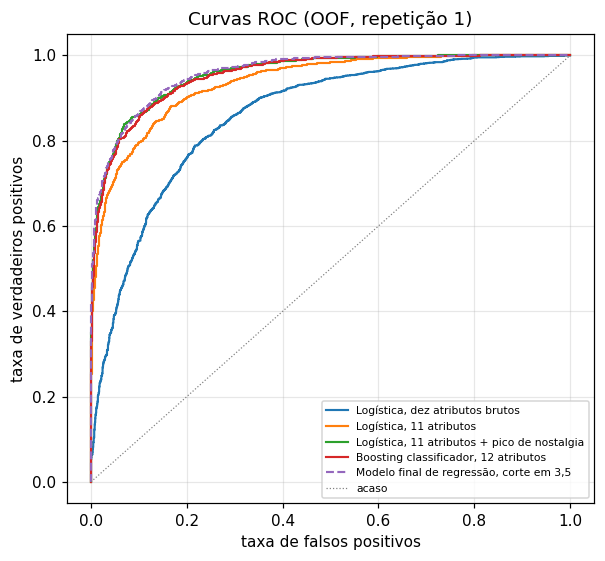

In [4]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
for i, name in enumerate(names):
    if name.startswith('Constante'):
        continue
    fpr, tpr, _ = roc_curve(liked, scores[name][0])
    ax.plot(fpr, tpr, lw=1.4, label=name, ls='--' if kinds[i] == 'nota' else '-')
ax.plot([0, 1], [0, 1], color='gray', lw=0.8, ls=':', label='acaso')
ax.set(xlabel='taxa de falsos positivos', ylabel='taxa de verdadeiros positivos',
       title='Curvas ROC (OOF, repetição 1)')
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

## 4. Calibração das probabilidades

Um classificador é **calibrado** quando, entre os pares a que ele dá probabilidade 0,7 de gostar, cerca de 70% de fato gostam. Agrupamos as probabilidades OOF em dez faixas e comparamos a média prevista com a proporção observada. A diagonal é a calibração perfeita.

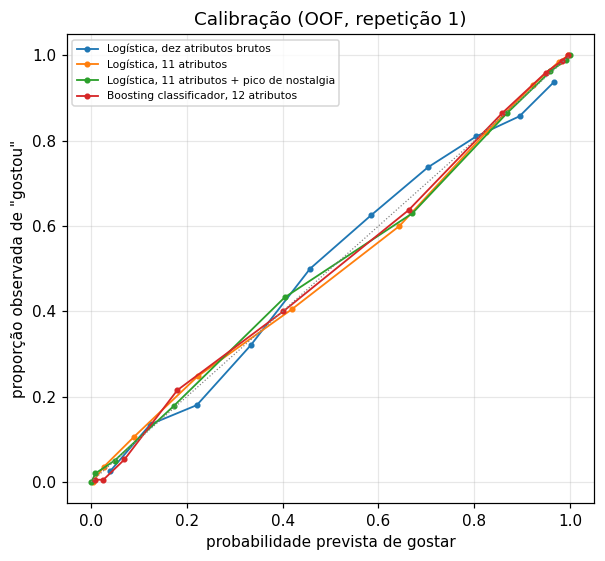

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
for i, name in enumerate(names):
    if kinds[i] != 'probabilidade' or name.startswith('Constante'):
        continue
    observed, predicted = calibration_curve(liked, scores[name][0], n_bins=10, strategy='quantile')
    ax.plot(predicted, observed, marker='o', ms=3, lw=1.2, label=name)
ax.plot([0, 1], [0, 1], color='gray', lw=0.8, ls=':')
ax.set(xlabel='probabilidade prevista de gostar', ylabel='proporção observada de "gostou"',
       title='Calibração (OOF, repetição 1)')
ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.show()

**Leitura**
- **As curvas ROC dos três melhores modelos praticamente se sobrepõem** (AUC entre 0,957 e 0,960). Todas ficam bem acima da logística nos atributos brutos (0,860). A curva tracejada é o modelo de regressão: a nota prevista também ordena bem os pares, mesmo sem ser uma probabilidade.
- **As probabilidades estão bem calibradas** em todos os modelos logísticos e no boosting: em cada faixa, a proporção observada fica a no máximo 0,045 da probabilidade prevista. Isso é esperado: os dois modelos são ajustados minimizando a log-loss, que recompensa probabilidades honestas. Com intercepto, a logística garante pelo menos que a probabilidade média no treino seja igual à proporção de "gostou".
- A calibração importa porque, com probabilidades confiáveis, o corte de 0,5 pode ser trocado por outro sem refazer o modelo. Uma plataforma poderia, por exemplo, só recomendar filmes com probabilidade acima de 0,8.

## 5. Onde os erros acontecem

Para cada nota real, a fração de pares classificados errado (previsões OOF da primeira repetição).

In [6]:
stars = oof['stars']
shown = ['Logística, 11 atributos + pico de nostalgia', 'Boosting classificador, 12 atributos',
         'Modelo final de regressão, corte em 3,5']
table = {}
for name in shown:
    kind = kinds[names.index(name)]
    decided = scores[name][0] >= (0.5 if kind == 'probabilidade' else 3.5)
    wrong = decided != (liked == 1)
    table[name] = [wrong[stars == k].mean() for k in range(6)]
table = pd.DataFrame(table, index=pd.Index(range(6), name='nota real'))
table.insert(0, 'pares', [int((stars == k).sum()) for k in range(6)])
display(table.style.format({c: '{:.1%}' for c in shown}))

,pares,"Logística, 11 atributos + pico de nostalgia","Boosting classificador, 12 atributos","Modelo final de regressão, corte em 3,5"
nota real,,,,
0,30,0.0%,0.0%,0.0%
1,180,0.0%,0.0%,0.0%
2,633,1.1%,1.1%,0.9%
3,1106,21.5%,22.1%,21.0%
4,1184,20.4%,20.4%,19.3%
5,867,0.6%,0.2%,0.5%


**Leitura**
- **Quase todos os erros estão nas notas 3 e 4**, a fronteira entre não gostar e gostar. Nessas notas, os três modelos erram cerca de 20% dos pares. Nas demais notas, erram no máximo 1,1%.
- Isso faz sentido. Uma nota 3 e uma nota 4 diferem por uma estrela, e o ruído irredutível visto na regressão (RMSE do modelo final ≈ 0,52) é da mesma ordem que a distância de cada uma até o corte de 3,5. Um par com nota esperada 3,6 cai num dos dois lados quase por sorte.
- Os modelos discordam entre si em só 5% dos pares (modelo de regressão contra boosting classificador). As três abordagens erram, em geral, nos mesmos pares de fronteira.

## 6. Hiperparâmetros escolhidos

In [7]:
for name, part in selections.groupby('modelo', sort=False):
    columns = [c for c in part.columns if c not in ('modelo', 'partição') and part[c].notna().any()]
    counts = part[columns].astype(str).agg(' | '.join, axis=1).value_counts()
    print(name, '—', ', '.join(columns))
    print(counts.to_string(), end='\n\n')

Logística, 11 atributos + pico de nostalgia — nostalgia__center, nostalgia__width
15.0 | 6.0    23
14.0 | 6.0     2

Boosting classificador, 12 atributos — l2_regularization, max_leaf_nodes, min_samples_leaf
0.0 | 7.0 | 20.0      8
0.0 | 7.0 | 60.0      8
0.0 | 15.0 | 60.0     6
0.0 | 15.0 | 20.0     2
10.0 | 15.0 | 60.0    1

Modelo final de regressão, corte em 3,5 — l2_regularization, max_leaf_nodes, min_samples_leaf
0.0 | 7.0 | 20.0      17
0.0 | 15.0 | 20.0      4
0.0 | 15.0 | 60.0      3
10.0 | 15.0 | 20.0     1



**Leitura**
- **No pico de nostalgia, a busca interna escolheu centro 15 e largura 6 em 23 das 25 partições**, os mesmos valores escolhidos na regressão (notebook 11). O formato do efeito de nostalgia não depende de como o alvo é medido.
- **O boosting classificador escolhe árvores mais simples que o regressor**: 7 folhas em 16 das 25 partições e mínimo de 60 linhas por folha em 15. Com um alvo binário, que carrega menos informação por linha, a busca prefere modelos mais regularizados. Ainda assim, o gap do boosting continua dez vezes maior que o da logística.

## 7. Conclusões

1. **A história da regressão se repete na classificação.** A construção de atributos traz os maiores ganhos (erro de 21,7% → 14,6%), e o boosting vence o modelo linear de onze atributos.
2. **A nostalgia explica a vantagem do boosting também aqui.** Com o pico de nostalgia, a regressão logística empata com o boosting classificador (12,1% contra 12,0%, p = 0,84), com gap dez vezes menor.
3. **O modelo final de regressão classifica tão bem quanto um classificador dedicado** (11,6% de erro, melhor em 20 das 25 partições, sem significância). Prever a nota e depois cortar não perde nada em relação a treinar direto o alvo binário. O contrário não vale: um classificador não prevê a nota, que é o que o RMSE avalia.
4. **Os erros restantes estão na fronteira 3 / 4**, onde o ruído irredutível do problema é da mesma ordem que a distância até o corte.

**Em termos do curso.** Com um alvo binário, a logística é o modelo linear natural: ela é linear no logaritmo da chance, $\log \frac{p}{1-p} = w^\top x$, assim como a regressão linear é linear na nota. Quando o conjunto de hipóteses linear recebe o atributo certo (o pico de nostalgia), seu viés cai até o nível do boosting, e sua variância continua bem menor, como mostra o gap. Também fica claro que o alvo binário tem menos informação: ele reduz o sinal disponível para aprender e favorece modelos mais simples. Por isso o modelo final continua sendo de regressão, como pede o enunciado.